# Does XGBoost Improve on Dynamic Ridge?

This is a controlled model comparison on the same 2021 WR route table, the same dynamic-context features, and five game-held-out folds stratified by week. Numeric imputation and categorical encoding are fit inside each training fold. Ridge remains the baseline; XGBoost uses a fixed, regularized configuration rather than tuning against held-out folds. We also report Extra Trees and histogram gradient boosting as context from the existing comparison.

Route-level RMSE is the primary model comparison. We also inspect calibration and whether the models' residuals repeat across independent game halves for a receiver. Better route prediction does not automatically mean better player evaluation.

In [1]:
from pathlib import Path
import math
import sys

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from IPython.display import SVG, display
from separation_over_expected.algorithm_comparison import compare_algorithms
from separation_over_expected.reports import read_csv_rows, write_csv

ROUTE_TABLE = PROJECT_ROOT / "data/processed/dynamic_features/pocket_context/route_level_snap_to_release_pocket.csv"
OUTPUT_DIR = PROJECT_ROOT / "data/processed/xgboost_comparison"
OUTPUT_FILES = {
    "predictions": OUTPUT_DIR / "route_oof_predictions.csv",
    "metrics": OUTPUT_DIR / "candidate_metrics.csv",
    "folds": OUTPUT_DIR / "fold_metrics.csv",
    "calibration": OUTPUT_DIR / "calibration_deciles.csv",
    "halves": OUTPUT_DIR / "receiver_half_scores.csv",
    "reliability": OUTPUT_DIR / "receiver_reliability.csv",
}

if all(path.exists() for path in OUTPUT_FILES.values()):
    tables = {name: read_csv_rows(path) for name, path in OUTPUT_FILES.items()}
else:
    if not ROUTE_TABLE.exists():
        raise FileNotFoundError("Build the dynamic route table and pocket-context features first.")
    result = compare_algorithms(
        read_csv_rows(ROUTE_TABLE),
        n_folds=5,
        min_routes_per_half=20,
        bootstrap_samples=1000,
        seed=42,
    )
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    tables = dict(zip(OUTPUT_FILES, result))
    for name, rows in tables.items():
        columns = list(dict.fromkeys(key for row in rows for key in row))
        write_csv(OUTPUT_FILES[name], columns, rows)

predictions = tables["predictions"]
metrics = tables["metrics"]
folds = tables["folds"]
calibration = tables["calibration"]
halves = tables["halves"]
reliability = tables["reliability"]
len(predictions), len({row["gameId"] for row in predictions}), len(metrics)

(20415, 122, 4)

## Route-level prediction

Paired game-bootstrap intervals compare each candidate's RMSE with Ridge on the same held-out routes. Negative RMSE differences favor the candidate. The fold panel shows how consistently the result holds across the five partitions.

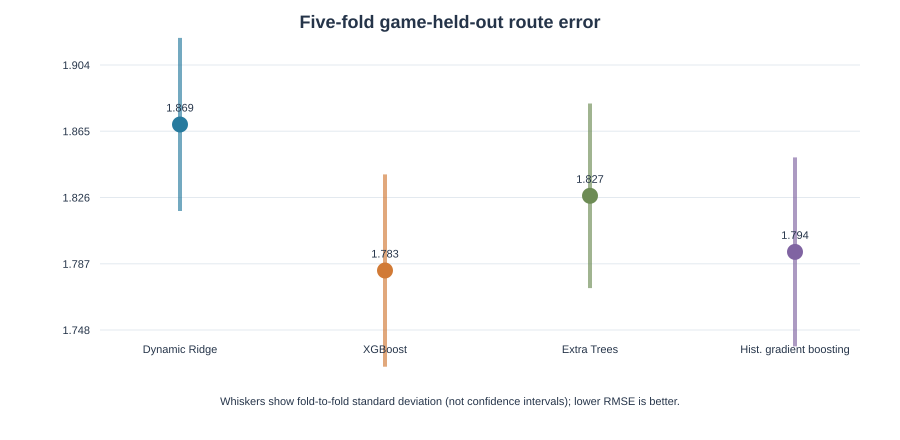

In [2]:
models = ["ridge_dynamic_context", "xgboost", "extra_trees", "hist_gradient_boosting"]
labels = {
    "ridge_dynamic_context": "Dynamic Ridge",
    "xgboost": "XGBoost",
    "extra_trees": "Extra Trees",
    "hist_gradient_boosting": "Hist. gradient boosting",
}
colors = {
    "ridge_dynamic_context": "#287b9e",
    "xgboost": "#d17a36",
    "extra_trees": "#6d8c55",
    "hist_gradient_boosting": "#8064a2",
}

def one_metric(model, source=metrics):
    return next(row for row in source if row["model"] == model)

def route_error_svg(metric_rows, fold_rows, width=900, height=440):
    visible = [row for row in metric_rows if row["model"] in models]
    low = min(float(row["rmse"]) for row in visible) - .035
    high = max(float(row["rmse"]) for row in visible) + .035
    left, right, top, bottom = 100, 860, 65, 330
    y = lambda value: bottom - (float(value) - low) / (high - low) * (bottom - top)
    xs = [180, 385, 590, 795]
    pieces = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        '<style>text{font-family:Arial,sans-serif;fill:#253449}.grid{stroke:#e3e9ef}</style>',
        '<text x="450" y="28" text-anchor="middle" font-size="18" font-weight="bold">Five-fold game-held-out route error</text>',
    ]
    for idx in range(5):
        value = low + (high - low) * idx / 4
        yy = y(value)
        pieces += [
            f'<line class="grid" x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}"/>',
            f'<text x="{left-10}" y="{yy+4:.1f}" text-anchor="end" font-size="11">{value:.3f}</text>',
        ]
    for x, name in zip(xs, models):
        row = one_metric(name)
        fold_values = [float(item["rmse"]) for item in fold_rows if item["model"] == name]
        mean = sum(fold_values) / len(fold_values)
        sd = math.sqrt(sum((value - mean) ** 2 for value in fold_values) / (len(fold_values) - 1))
        median = float(row["rmse"])
        pieces += [
            f'<line x1="{x}" y1="{y(median-sd):.1f}" x2="{x}" y2="{y(median+sd):.1f}" stroke="{colors[name]}" stroke-width="4" opacity=".65"/>',
            f'<circle cx="{x}" cy="{y(median):.1f}" r="8" fill="{colors[name]}"><title>RMSE {median:.3f}; MAE {float(row["mae"]):.3f}</title></circle>',
            f'<text x="{x}" y="{bottom+23}" text-anchor="middle" font-size="11">{labels[name]}</text>',
            f'<text x="{x}" y="{y(median)-13:.1f}" text-anchor="middle" font-size="11">{median:.3f}</text>',
        ]
    pieces += [
        '<text x="450" y="405" text-anchor="middle" font-size="11">Whiskers show fold-to-fold standard deviation (not confidence intervals); lower RMSE is better.</text>',
        '</svg>',
    ]
    return "".join(pieces)

display(SVG(route_error_svg(metrics, folds)))

In [3]:
route_table = []
for model in models:
    row = one_metric(model)
    route_table.append({
        "model": labels[model],
        "routes": row["n"],
        "RMSE": f'{float(row["rmse"]):.3f}',
        "MAE": f'{float(row["mae"]):.3f}',
        "R²": f'{float(row["r2"]):.3f}',
        "RMSE change vs Ridge (95% game bootstrap)": (
            "baseline" if model == "ridge_dynamic_context" else
            f'{float(row["rmse_delta_vs_ridge"]):+.3f} '
            f'[{float(row["rmse_delta_lower_95"]):+.3f}, {float(row["rmse_delta_upper_95"]):+.3f}]'
        ),
    })
display(route_table)

[{'model': 'Dynamic Ridge',
  'routes': '20415',
  'RMSE': '1.869',
  'MAE': '1.363',
  'R²': '0.508',
  'RMSE change vs Ridge (95% game bootstrap)': 'baseline'},
 {'model': 'XGBoost',
  'routes': '20415',
  'RMSE': '1.783',
  'MAE': '1.273',
  'R²': '0.552',
  'RMSE change vs Ridge (95% game bootstrap)': '-0.086 [-0.100, -0.073]'},
 {'model': 'Extra Trees',
  'routes': '20415',
  'RMSE': '1.827',
  'MAE': '1.312',
  'R²': '0.530',
  'RMSE change vs Ridge (95% game bootstrap)': '-0.042 [-0.053, -0.032]'},
 {'model': 'Hist. gradient boosting',
  'routes': '20415',
  'RMSE': '1.794',
  'MAE': '1.284',
  'R²': '0.547',
  'RMSE change vs Ridge (95% game bootstrap)': '-0.075 [-0.088, -0.062]'}]

## Calibration

The decile plot compares mean predicted separation change with mean observed change. Calibration slope near 1 and small decile residuals are desirable. A flexible model can lower RMSE while becoming poorly calibrated, so we inspect this separately.

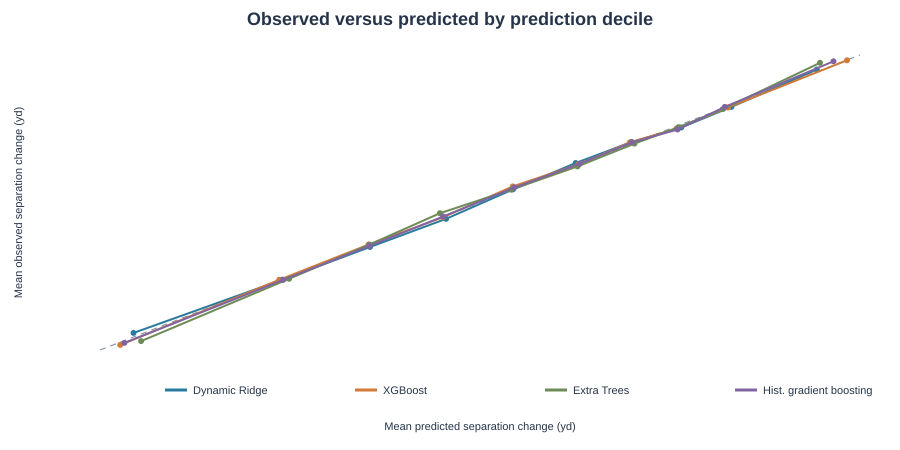

[{'model': 'Dynamic Ridge',
  'calibration_slope': 0.997,
  'calibration_intercept': -0.006,
  'mean_absolute_decile_bias': 0.051},
 {'model': 'Extra Trees',
  'calibration_slope': 1.03,
  'calibration_intercept': 0.07,
  'mean_absolute_decile_bias': 0.068},
 {'model': 'Hist. gradient boosting',
  'calibration_slope': 1.013,
  'calibration_intercept': 0.03,
  'mean_absolute_decile_bias': 0.037},
 {'model': 'XGBoost',
  'calibration_slope': 1.002,
  'calibration_intercept': 0.004,
  'mean_absolute_decile_bias': 0.034}]

In [4]:
def calibration_svg(rows, width=900, height=450):
    left, right, top, bottom = 100, 860, 55, 350
    values = [float(row[key]) for row in rows for key in ("mean_actual", "mean_predicted")]
    low, high = min(values) - .12, max(values) + .12
    x = lambda value: left + (float(value) - low) / (high - low) * (right - left)
    y = lambda value: bottom - (float(value) - low) / (high - low) * (bottom - top)
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        '<style>text{font-family:Arial,sans-serif;fill:#253449}.grid{stroke:#e3e9ef}</style>',
        '<text x="450" y="25" text-anchor="middle" font-size="18" font-weight="bold">Observed versus predicted by prediction decile</text>',
        f'<line x1="{x(low):.1f}" y1="{y(low):.1f}" x2="{x(high):.1f}" y2="{y(high):.1f}" stroke="#788796" stroke-dasharray="6 5"/>',
    ]
    for model in models:
        points = sorted((row for row in rows if row["model"] == model), key=lambda row: int(row["decile"]))
        coords = " ".join(f'{x(row["mean_predicted"]):.1f},{y(row["mean_actual"]):.1f}' for row in points)
        parts.append(f'<polyline points="{coords}" fill="none" stroke="{colors[model]}" stroke-width="2"/>')
        for row in points:
            xx, yy = x(row["mean_predicted"]), y(row["mean_actual"])
            parts.append(f'<circle cx="{xx:.1f}" cy="{yy:.1f}" r="3" fill="{colors[model]}"><title>{labels[model]}, decile {row["decile"]}</title></circle>')
    for index, model in enumerate(models):
        xx = 165 + index * 190
        parts += [f'<line x1="{xx}" y1="390" x2="{xx+22}" y2="390" stroke="{colors[model]}" stroke-width="3"/>',
                  f'<text x="{xx+28}" y="394" font-size="11">{labels[model]}</text>']
    parts += ['<text x="480" y="430" text-anchor="middle" font-size="11">Mean predicted separation change (yd)</text>',
              f'<text x="22" y="{(top+bottom)/2}" text-anchor="middle" font-size="11" transform="rotate(-90 22 {(top+bottom)/2})">Mean observed separation change (yd)</text>',
              '</svg>']
    return "".join(parts)

display(SVG(calibration_svg(calibration)))
[{"model": labels[row["model"]], "calibration_slope": round(float(row["calibration_slope"]), 3),
  "calibration_intercept": round(float(row["calibration_intercept"]), 3),
  "mean_absolute_decile_bias": round(float(row["mean_absolute_decile_bias"]), 3)}
 for row in metrics if row["model"] in models]

## Does route accuracy carry over to receiver repeatability?

Split-half reliability correlates each eligible receiver's mean route residual between two disjoint sets of games. Paired intervals compare changes from Ridge. This is a diagnostic for persistence, not proof that residuals isolate receiver skill.

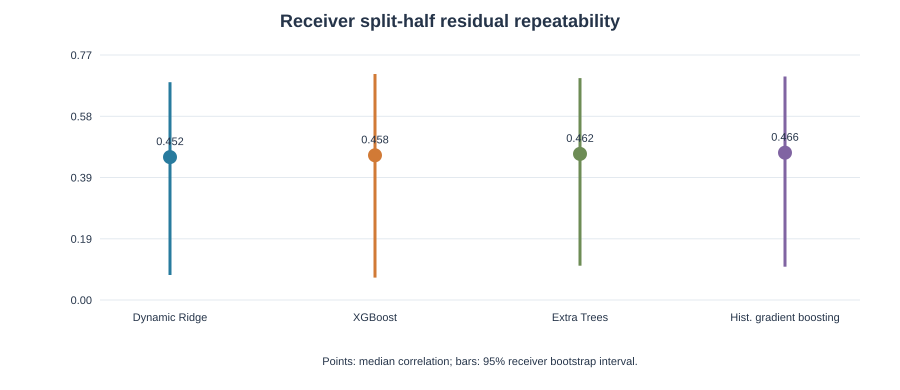

[{'model': 'Dynamic Ridge',
  'eligible_receivers': '115',
  'Pearson': '0.451857',
  'Pearson change vs Ridge': '0',
  'change interval': '[0, 0]',
  'Spearman': '0.209469'},
 {'model': 'Extra Trees',
  'eligible_receivers': '115',
  'Pearson': '0.462143',
  'Pearson change vs Ridge': '0.010286',
  'change interval': '[-0.065212, 0.090557]',
  'Spearman': '0.279082'},
 {'model': 'Hist. gradient boosting',
  'eligible_receivers': '115',
  'Pearson': '0.465955',
  'Pearson change vs Ridge': '0.014098',
  'change interval': '[-0.078247, 0.113394]',
  'Spearman': '0.287943'},
 {'model': 'XGBoost',
  'eligible_receivers': '115',
  'Pearson': '0.457505',
  'Pearson change vs Ridge': '0.005648',
  'change interval': '[-0.107040, 0.105242]',
  'Spearman': '0.252387'}]

In [5]:
def reliability_svg(rows, width=900, height=390):
    left, right, top, bottom = 100, 860, 55, 300
    entries = [row for row in rows if row["model"] in models]
    low = min(0, min(float(row["pearson_ci_lower"]) for row in entries) - .06)
    high = max(float(row["pearson_ci_upper"]) for row in entries) + .06
    y = lambda value: bottom - (float(value) - low) / (high - low) * (bottom - top)
    pieces = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        '<style>text{font-family:Arial,sans-serif;fill:#253449}.grid{stroke:#e3e9ef}</style>',
        '<text x="450" y="27" text-anchor="middle" font-size="18" font-weight="bold">Receiver split-half residual repeatability</text>',
    ]
    for index in range(5):
        value = low + (high - low) * index / 4
        yy = y(value)
        pieces += [f'<line class="grid" x1="{left}" y1="{yy:.1f}" x2="{right}" y2="{yy:.1f}"/>',
                   f'<text x="{left-8}" y="{yy+4:.1f}" text-anchor="end" font-size="11">{value:.2f}</text>']
    for index, model in enumerate(models):
        row = next(row for row in entries if row["model"] == model)
        x = 170 + index * 205
        pieces += [f'<line x1="{x}" y1="{y(row["pearson_ci_lower"]):.1f}" x2="{x}" y2="{y(row["pearson_ci_upper"]):.1f}" stroke="{colors[model]}" stroke-width="3"/>',
                   f'<circle cx="{x}" cy="{y(row["pearson"]):.1f}" r="7" fill="{colors[model]}"/>',
                   f'<text x="{x}" y="{bottom+21}" text-anchor="middle" font-size="11">{labels[model]}</text>',
                   f'<text x="{x}" y="{y(row["pearson"])-12:.1f}" text-anchor="middle" font-size="11">{float(row["pearson"]):.3f}</text>']
    pieces += ['<text x="480" y="365" text-anchor="middle" font-size="11">Points: median correlation; bars: 95% receiver bootstrap interval.</text>', '</svg>']
    return "".join(pieces)

display(SVG(reliability_svg(reliability)))
[{"model": labels[row["model"]], "eligible_receivers": row["eligible_receivers"],
  "Pearson": row["pearson"], "Pearson change vs Ridge": row["pearson_delta_vs_ridge"],
  "change interval": f'[{row["pearson_delta_lower_95"]}, {row["pearson_delta_upper_95"]}]',
  "Spearman": row["spearman"]}
 for row in reliability if row["model"] in models]

## Reading the result

Treat a route-level RMSE win as evidence that the model predicts this measured target better, not as evidence that it has discovered receiver talent. The receiver repeatability and calibration sections show whether that predictive gain carries into the project’s player-evaluation use case. The folds are all from 2021, so any selected winner still needs a later-season check.

In [6]:
xgb = one_metric("xgboost")
ridge = one_metric("ridge_dynamic_context")
xgb_reliability = next(row for row in reliability if row["model"] == "xgboost")
rmse_delta = float(xgb["rmse_delta_vs_ridge"])
rmse_ci = (float(xgb["rmse_delta_lower_95"]), float(xgb["rmse_delta_upper_95"]))
if rmse_ci[1] < 0:
    route_conclusion = "XGBoost has lower game-held-out route RMSE than Ridge, with the paired interval below zero."
elif rmse_ci[0] > 0:
    route_conclusion = "XGBoost has higher game-held-out route RMSE than Ridge, with the paired interval above zero."
else:
    route_conclusion = "The paired game-bootstrap interval does not establish a route-RMSE difference between XGBoost and Ridge."
route_conclusion, f"ΔRMSE={rmse_delta:+.3f} yd; 95% CI [{rmse_ci[0]:+.3f}, {rmse_ci[1]:+.3f}]", \
    f"receiver Pearson={float(xgb_reliability['pearson']):.3f}; change vs Ridge={float(xgb_reliability['pearson_delta_vs_ridge']):+.3f}"

('XGBoost has lower game-held-out route RMSE than Ridge, with the paired interval below zero.',
 'ΔRMSE=-0.086 yd; 95% CI [-0.100, -0.073]',
 'receiver Pearson=0.458; change vs Ridge=+0.006')